# Part 1: Setting up the Environment

In [ ]:
import os
import shutil
import pandas as pd
import random
import numpy as np

import tensorflow as tf
print(f"Tensorflow Version: {tf.__version__}")

import keras
print(f"Keras Version: {keras.__version__}")

Tensorflow Version: 2.21.0
Keras Version: 3.13.2


In [ ]:
# seed = random.randint(0, 1000)
seed=108
# Set random seeds
os.environ["PYTHONHASHSEED"]=str(seed)
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)
print(f"SEED: {seed}")

SEED: 108


In [ ]:
def create_dir(path):
    if not os.path.exists(path):
        os.makedirs(path)
        print(f"{path} Folder Created Succesfully")

# Part 2: Find Number Of Class and Their Occurance

In [ ]:
from google.colab import files
import zipfile
import os

print("Please click 'Choose Files' below to upload your dataset zip file (e.g., archive.zip):")
uploaded = files.upload()

# Automatically grab the name of the uploaded zip file
zip_file_path = list(uploaded.keys())[0] if uploaded else None
extract_path = '/content/extracted_data'

if zip_file_path:
    os.makedirs(extract_path, exist_ok=True)
    print(f"Extracting {zip_file_path}...")
    with zipfile.ZipFile(zip_file_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("Dataset extracted successfully!")
else:
    print("No file was uploaded. Please re-run the cell and select your zip file.")

# Re-initialize your working directories
os.makedirs("/content/dawn/images", exist_ok=True)
os.makedirs("/content/dawn/labels", exist_ok=True)
os.makedirs("/content/split_yolo/train/images", exist_ok=True)
os.makedirs("/content/split_yolo/train/labels", exist_ok=True)
os.makedirs("/content/split_yolo/test/images", exist_ok=True)
os.makedirs("/content/split_yolo/test/labels", exist_ok=True)

print("Directories initialized and ready for training!")

Please click 'Choose Files' below to upload your dataset zip file (e.g., archive.zip):


Saving archive.zip to archive (1).zip
Extracting archive (1).zip...
Dataset extracted successfully!
Directories initialized and ready for training!


In [ ]:
import os

print("Files and folders in /content/:")
print(os.listdir("/content"))

Files and folders in /content/:
['.config', 'drive', 'archive (1).zip', 'archive.zip', 'dawn', 'split_yolo', 'extracted_data', 'sample_data']


In [ ]:
import shutil, os

# remove the Mac junk folder
shutil.rmtree("/content/extracted_data/__MACOSX", ignore_errors=True)

# find the real labels and images folders
for root, dirs, files in os.walk("/content/extracted_data"):
    if os.path.basename(root) == "labels":
        LABELS = root
    if os.path.basename(root) == "images":
        IMAGES = root
print("labels:", LABELS)
print("images:", IMAGES)
print(len(os.listdir(LABELS)), "label files,", len(os.listdir(IMAGES)), "images")

labels: /content/extracted_data/archive/labels
images: /content/extracted_data/archive/images
1027 label files, 1027 images


In [ ]:
import os
import pandas as pd

# Dynamically search for the 'labels' directory within /content/extracted_data
extract_path = "/content/extracted_data"
folder_path = None

for root, dirs, files in os.walk(extract_path):
    if "labels" in dirs:
        folder_path = os.path.join(root, "labels")
        break

if not folder_path or not os.path.exists(folder_path):
    # Fallback default if not found dynamically
    folder_path = "/content/extracted_data/archive/labels"

print(f"Using labels folder path: {folder_path}")

try:
    file_names = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f)) and not f.startswith('.')]
except FileNotFoundError as e:
    print(f"Error: The directory {folder_path} was not found. Please verify the ZIP file structure.")
    file_names = []

data = []
for file_name in file_names:
    file_path = os.path.join(folder_path, file_name)
    try:
        with open(file_path, 'r') as file:
            for line in file:
                line = line.strip()
                if line:  # Skip empty lines
                    # YOLO format lines start with the class ID, separated by spaces
                    class_id = line.split()[0]
                    data.append(class_id)
    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

print(f"Total class IDs collected: {len(data)}")

# Safely create DataFrame and count levels only if data is not empty
if len(data) > 0:
    df = pd.DataFrame(data, columns=['level'])
    level_counts = df['level'].value_counts()
    display(level_counts)
else:
    print("Warning: No class IDs were found. Please check your folder path.")

Using labels folder path: /content/extracted_data/archive/labels
Total class IDs collected: 7846


,count
level,
3,6454
8,646
1,477
6,161
4,81
2,26
7,1


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
PROJECT = "/content/drive/MyDrive/csc490_runs"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


^ that connects it to google drive so that the files get saved

# Part 3: Remove Least Class with 1 Appearance

In [ ]:
import os
import shutil

# 1. Update paths for Google Colab (corrected to point directly to extracted labels)
source_folder = LABELS
destination_folder = '/content/dawn/labels'

# 2. Automatically create the destination folder if it doesn't exist yet
os.makedirs(destination_folder, exist_ok=True)

# Safety check for avoid_file_id just in case it wasn't defined yet
avoid_file_id = locals().get('avoid_file_id', '')

# 3. Copy all files
for filename in os.listdir(source_folder):
    # Skip hidden Mac files like .DS_Store
    if filename.startswith('.'):
        continue

    if filename.split(".")[0] == avoid_file_id:
        print(f"Do Not Copy this file {filename}")
    else:
        source_path = os.path.join(source_folder, filename)
        destination_path = os.path.join(destination_folder, filename)

        if os.path.isfile(source_path):
            shutil.copy2(source_path, destination_path)  # copy2 preserves metadata

print("Files copied successfully!")

Files copied successfully!


In [ ]:
import os, shutil, collections

source_folder = IMAGES
destination_folder = '/content/dawn/images'
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

shutil.rmtree(destination_folder, ignore_errors=True)   # wipes the old .txt files too
os.makedirs(destination_folder, exist_ok=True)

for filename in os.listdir(source_folder):
    if filename.startswith('.') or not filename.lower().endswith(IMG_EXT):
        continue
    shutil.copy2(os.path.join(source_folder, filename), os.path.join(destination_folder, filename))

print("Images copied:", len(os.listdir(destination_folder)))
print(collections.Counter(os.path.splitext(f)[1].lower() for f in os.listdir(destination_folder)))

Images copied: 1027
Counter({'.jpg': 1027})


In [ ]:
import os
import pandas as pd

# 1. Update to your local Colab path
folder_path = "/content/dawn/labels"

# Get all valid file names (ignoring hidden Mac files like .DS_Store)
file_names = [f for f in os.listdir(folder_path) if os.path.isfile(os.path.join(folder_path, f)) and not f.startswith('.')]

data = []
for file_name in file_names:
    file_path = os.path.join(folder_path, file_name)
    try:
        with open(file_path, 'r') as file:
            for line in file:
                line = line.strip()
                if line:
                    # YOLO format lines start with the class ID separated by spaces
                    parts = line.split()
                    data.append(parts[0])
    except Exception as e:
        print(f"Error reading file {file_name}: {e}")

# 2. Safely create DataFrame and get counts
if len(data) > 0:
    df = pd.DataFrame(data, columns=['level'])
    level_counts = df['level'].value_counts()
    display(level_counts)
else:
    print("Warning: No label data was found. Please check your folder path.")

,count
level,
3,6454
8,646
1,477
6,161
4,81
2,26
7,1


In [ ]:
import glob, numpy as np
NAMES = ['truck','person','bicycle','car','motorcycle','bus']

def count_classes(label_dir, nc=6):
    counts = np.zeros(nc)
    for f in glob.glob(f"{label_dir}/*.txt"):
        for line in open(f):
            if line.strip():
                counts[int(line.split()[0])] += 1
    return counts

train_counts = count_classes("/content/split_yolo/train/labels")

def compute_weights(counts, alpha):
    counts = np.maximum(counts, 1)
    return (counts.sum() / (len(counts) * counts)) ** alpha

print(dict(zip(NAMES, train_counts)))
for a in [0, 0.5, 1]:
    print("alpha =", a, dict(zip(NAMES, compute_weights(train_counts, a).round(2))))

{'truck': np.float64(0.0), 'person': np.float64(0.0), 'bicycle': np.float64(0.0), 'car': np.float64(0.0), 'motorcycle': np.float64(0.0), 'bus': np.float64(0.0)}
alpha = 0 {'truck': np.float64(1.0), 'person': np.float64(1.0), 'bicycle': np.float64(1.0), 'car': np.float64(1.0), 'motorcycle': np.float64(1.0), 'bus': np.float64(1.0)}
alpha = 0.5 {'truck': np.float64(1.0), 'person': np.float64(1.0), 'bicycle': np.float64(1.0), 'car': np.float64(1.0), 'motorcycle': np.float64(1.0), 'bus': np.float64(1.0)}
alpha = 1 {'truck': np.float64(1.0), 'person': np.float64(1.0), 'bicycle': np.float64(1.0), 'car': np.float64(1.0), 'motorcycle': np.float64(1.0), 'bus': np.float64(1.0)}


In [ ]:
import os
for p in ["/content/extracted_data", "/content/dawn/labels",
          "/content/split_yolo/train/labels", "/content/split_yolo/val/labels"]:
    print(p, "->", len(os.listdir(p)) if os.path.exists(p) else "DOES NOT EXIST")

/content/extracted_data -> 1
/content/dawn/labels -> 1027
/content/split_yolo/train/labels -> 0
/content/split_yolo/val/labels -> DOES NOT EXIST


# Part 4: Train-Validation Split (80-20)

In [ ]:
import os, shutil
import pandas as pd
from sklearn.model_selection import train_test_split

IMG_DIR = "/content/dawn/images"
LABEL_DIR = "/content/dawn/labels"

def weather_of(stem):
    s = stem.lower()
    if s.startswith("snow"): return "snow"
    if s.startswith("sand") or s.startswith("dust"): return "sand"
    if s.startswith("rain") or s.startswith("mist"): return "rain"
    return "fog"          # haze, foggy

rarity = sorted(range(6), key=lambda i: c[i])      # rarest class first
rows = []
for img in sorted(f for f in os.listdir(IMG_DIR) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp', '.webp'))):
    if img.startswith('.'): continue
    stem = os.path.splitext(img)[0]
    lbl = f"{LABEL_DIR}/{stem}.txt"
    cls = {int(l.split()[0]) for l in open(lbl) if l.strip()} if os.path.exists(lbl) else set()
    rows.append(dict(img=img, stem=stem, weather=weather_of(stem),
                     rarest=next((k for k in rarity if k in cls), -1)))
df = pd.DataFrame(rows)
print(df.weather.value_counts())                    # check against 218 / 282 / 204 / 323

df["strata"] = df.weather + "_" + df.rarest.astype(str)
counts_s = df.strata.value_counts()
df.loc[df.strata.map(counts_s) < 5, "strata"] = "misc"      # pool all tiny strata into one group
if (df.strata == "misc").sum() < 2:                           # safety: fold a lone leftover into the biggest group
    df.loc[df.strata == "misc", "strata"] = df.strata.value_counts().index[0]
print(df.strata.value_counts().tail(5))                       # smallest group should now be >= 2
train_df, val_df = train_test_split(df, test_size=0.2, stratify=df.strata, random_state=42)
print(pd.DataFrame({"train": train_df.weather.value_counts(), "val": val_df.weather.value_counts()}))

shutil.rmtree("/content/split_yolo", ignore_errors=True)
for name, part in [("train", train_df), ("val", val_df)]:
    for sub in ("images", "labels"):
        os.makedirs(f"/content/split_yolo/{name}/{sub}")
    for _, r in part.iterrows():
        shutil.copy2(f"{IMG_DIR}/{r.img}", f"/content/split_yolo/{name}/images/{r.img}")
        if os.path.exists(f"{LABEL_DIR}/{r.stem}.txt"):
            shutil.copy2(f"{LABEL_DIR}/{r.stem}.txt", f"/content/split_yolo/{name}/labels/{r.stem}.txt")

NAMES = ['truck','person','bicycle','car','motorcycle','bus']
tr, va = count("/content/split_yolo/train/labels"), count("/content/split_yolo/val/labels")

print(pd.DataFrame({"train": [tr[i] for i in range(6)], "val": [va[i] for i in range(6)]}, index=NAMES))
print(len(train_df), "train images,", len(val_df), "val images")

weather
sand    323
rain    282
fog     218
snow    204
Name: count, dtype: int64
strata
snow_5    15
fog_4     14
misc      10
sand_2     9
fog_2      6
Name: count, dtype: int64
         train  val
weather            
sand       258   65
rain       226   56
fog        174   44
snow       163   41
            train   val
truck         533   113
person        364   113
bicycle        21     5
car          5279  1175
motorcycle     56    25
bus           128    33
821 train images, 206 val images


In [ ]:
%matplotlib inline

import numpy as np
import matplotlib.pyplot as plt
import random
import os
import cv2
import shutil
import tqdm
import glob

In [ ]:
# Check GPU is working or not
import torch
print(f"Using torch {torch.__version__} ({torch.cuda.get_device_properties(0).name if torch.cuda.is_available() else 'CPU'})")

Using torch 2.14.1+cu130 (Tesla T4)


In [ ]:
 # Install ultralytics
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 46.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [ ]:
from ultralytics import YOLO

# load pre-trained model
detection_model = YOLO("yolov8m.pt")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings



# Part 5: Create Data.yaml File

In [ ]:
open("/content/data.yaml", "w").write("""path: /content/split_yolo
train: train/images
val: val/images
nc: 6
names: ['truck','person','bicycle','car','motorcycle','bus']
""")
print(open("/content/data.yaml").read())

path: /content/split_yolo
train: train/images
val: val/images
nc: 6
names: ['truck','person','bicycle','car','motorcycle','bus']



# Part 6: Calculate Class Weights

In [ ]:
import json, math
counts = [max(tr[i], 1) for i in range(6)]
N, K = sum(counts), 6
w_inv  = [N / (K * n) for n in counts]
w_sqrt = [math.sqrt(w) for w in w_inv]
json.dump({"classes": NAMES, "train_counts": counts, "w_inverse": w_inv, "w_sqrt": w_sqrt},
          open("/content/class_weights.json", "w"), indent=2)
for n, cnt, a, b in zip(NAMES, counts, w_inv, w_sqrt):
    print(f"{n:11s} {cnt:5d}  inverse={a:6.2f}  sqrt={b:5.2f}")

truck         533  inverse=  2.00  sqrt= 1.41
person        364  inverse=  2.92  sqrt= 1.71
bicycle        21  inverse= 50.64  sqrt= 7.12
car          5279  inverse=  0.20  sqrt= 0.45
motorcycle     56  inverse= 18.99  sqrt= 4.36
bus           128  inverse=  8.31  sqrt= 2.88


# Part 7: Train Model

In [ ]:
import os, collections
for s in ["train", "val"]:
    d = f"/content/split_yolo/{s}/images"
    print(s, collections.Counter(os.path.splitext(f)[1] for f in os.listdir(d)),
          len(os.listdir(f"/content/split_yolo/{s}/labels")), "label files")

train Counter({'.jpg': 821}) 821 label files
val Counter({'.jpg': 206}) 206 label files


In [ ]:
!rm -f /content/split_yolo/train/labels.cache /content/split_yolo/val/labels.cache

import yaml
import os
import random
import matplotlib.pyplot as plt
from ultralytics import YOLO

yaml_path = "/content/data.yaml"

# 1. Read existing data.yaml if it exists
if os.path.exists(yaml_path):
    with open(yaml_path, "r") as f:
        data = yaml.safe_load(f) or {}
else:
    data = {}

# 2. Update paths for Google Colab
data["path"] = "/content/split_yolo"
data["train"] = "train/images"
data["val"] = "val/images"

# Preserve class names if already defined
if "names" not in data:
    data["names"] = {
        0: "truck",
        1: "person",
        2: "bicycle",
        3: "car",
        4: "motorcycle",
        5: "bus"
    }

data["nc"] = len(data["names"])

# 3. Overwrite data.yaml with the updated paths
with open(yaml_path, "w") as f:
    yaml.dump(data, f, sort_keys=False)

print("Successfully updated data.yaml! Current contents:")
print("-" * 40)

with open(yaml_path, "r") as f:
    print(f.read())

print("-" * 40)

# 4. Train the YOLOv8 model
model = YOLO("yolov8m.pt")

# Use 3 epochs for a quick test
model.train(data=yaml_path, epochs=3, seed=108, name="baseline_test")

# For full training, use:
# model.train(data=yaml_path, epochs=130, seed=108, name="baseline")

Successfully updated data.yaml! Current contents:
----------------------------------------
path: /content/split_yolo
train: train/images
val: val/images
nc: 6
names:
- truck
- person
- bicycle
- car
- motorcycle
- bus

----------------------------------------
Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7da5284d0b00>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
     

/content/runs/detect/baseline_test/


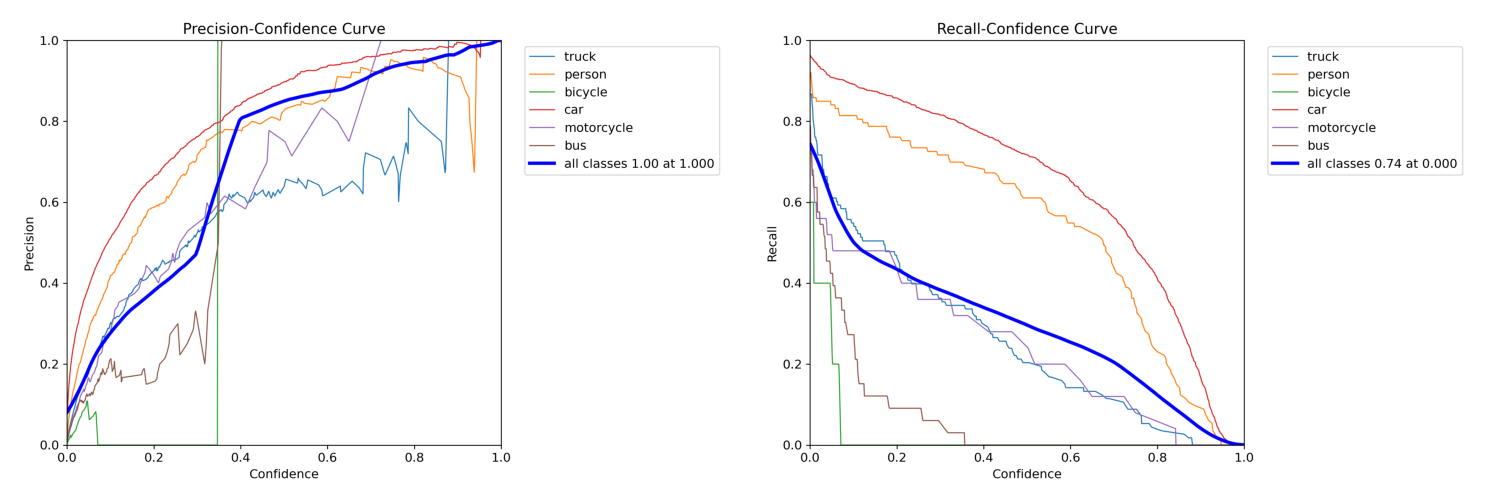

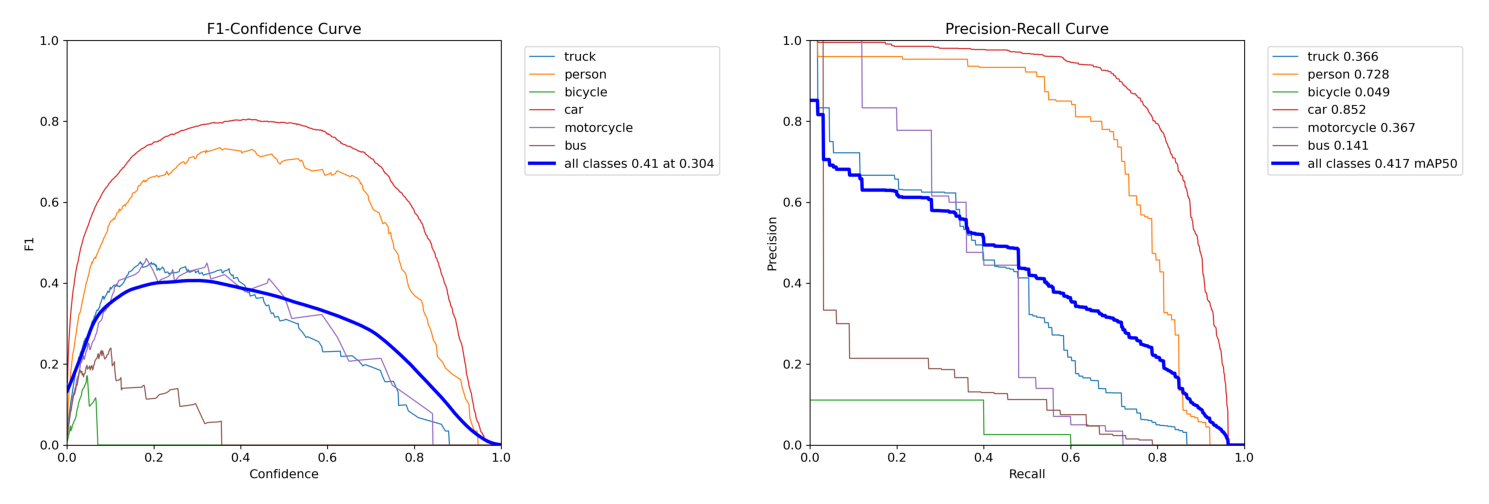

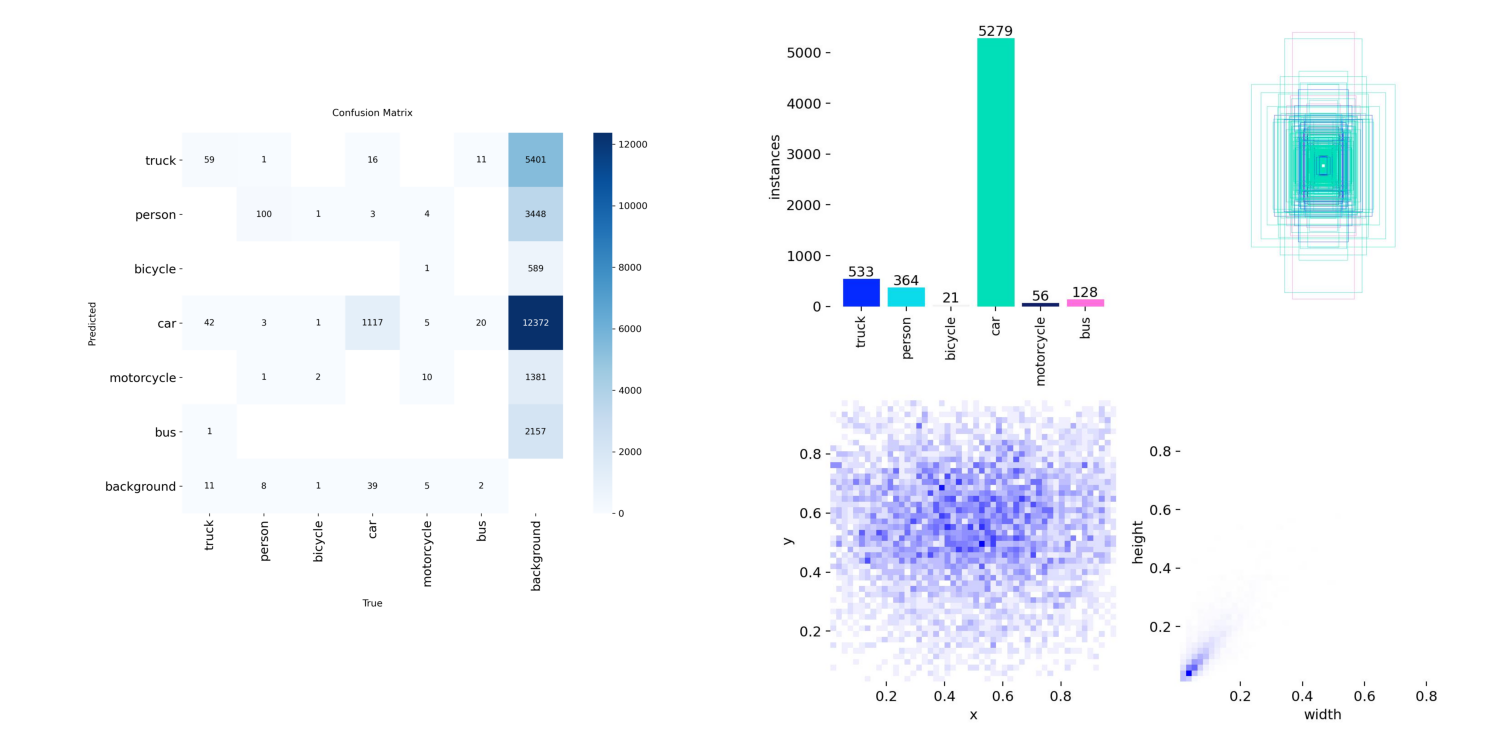

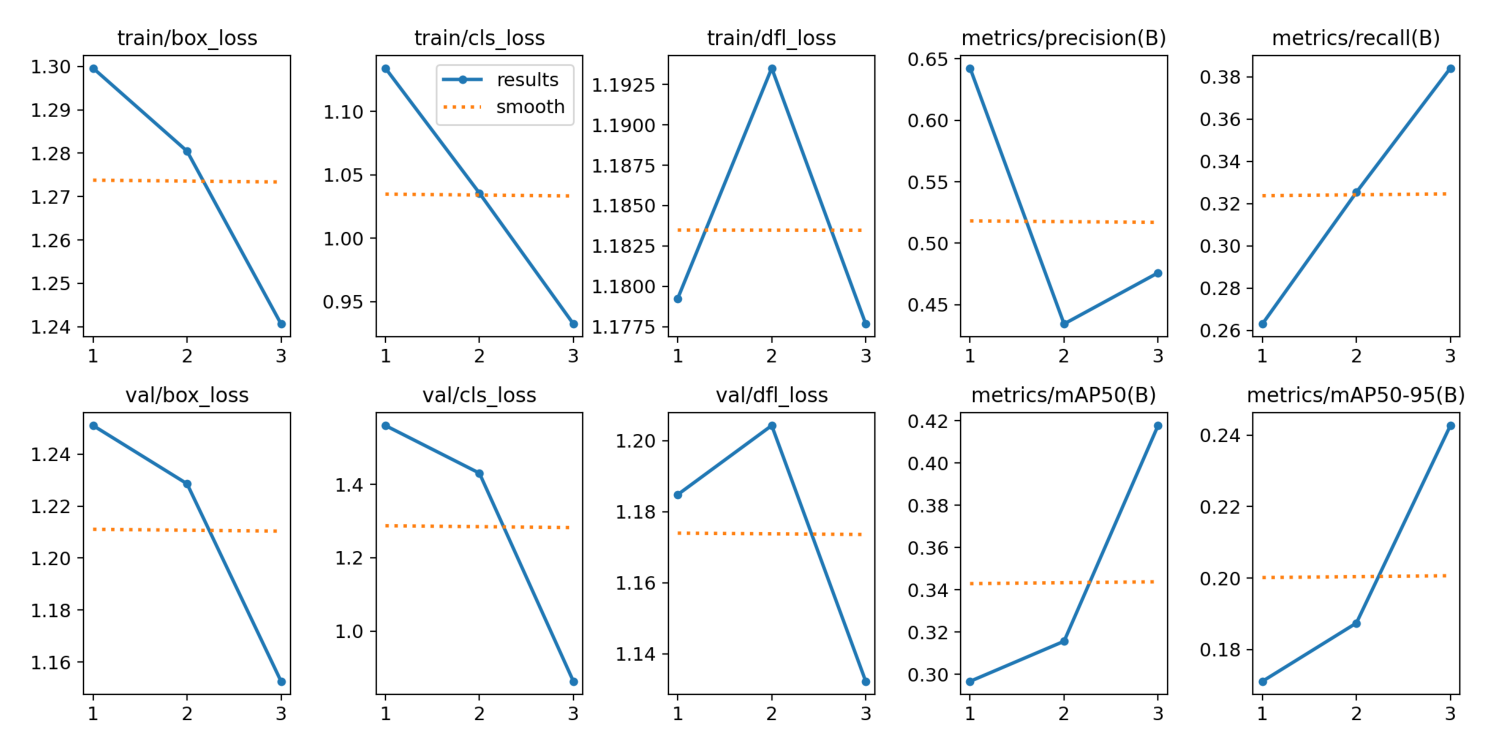

In [ ]:
# 5. Set the directory containing training results
model_path = str(model.trainer.save_dir) + "/"
print(model_path)

def plot(ls, size):
    c = 1
    plt.figure(figsize=(15, 10))

    for im in ls:
        image_path = os.path.join(model_path, im)

        if os.path.exists(image_path):
            plt.subplot(size[0], size[1], c)
            image = plt.imread(image_path)
            plt.imshow(image)
            plt.axis("off")
            c += 1
        else:
            print(f"Warning: Could not find {image_path}")

    plt.tight_layout()
    plt.show()

# 6. Plot training metrics
plot(["BoxP_curve.png", "BoxR_curve.png"], (1, 2))
plot(["BoxF1_curve.png", "BoxPR_curve.png"], (1, 2))
plot(["confusion_matrix.png", "labels.jpg"], (1, 2))
plot(["results.png"], (1, 1))


image 1/1 /content/split_yolo/val/images/snow_storm-341.jpg: 448x640 1 person, 2 cars, 29.4ms
Speed: 2.7ms preprocess, 29.4ms inference, 1.7ms postprocess per image at shape (1, 3, 448, 640)
Results saved to /content/runs/detect/predict

image 1/1 /content/split_yolo/val/images/sand_storm-332.jpg: 480x640 1 car, 32.1ms
Speed: 1.7ms preprocess, 32.1ms inference, 1.7ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict

image 1/1 /content/split_yolo/val/images/haze-096.jpg: 416x640 3 cars, 37.0ms
Speed: 1.6ms preprocess, 37.0ms inference, 1.6ms postprocess per image at shape (1, 3, 416, 640)
Results saved to /content/runs/detect/predict

image 1/1 /content/split_yolo/val/images/sand_storm-363.jpg: 640x480 1 person, 3 cars, 30.1ms
Speed: 2.2ms preprocess, 30.1ms inference, 1.6ms postprocess per image at shape (1, 3, 640, 480)
Results saved to /content/runs/detect/predict

image 1/1 /content/split_yolo/val/images/sand_storm-204.jpg: 480x640 1 tru

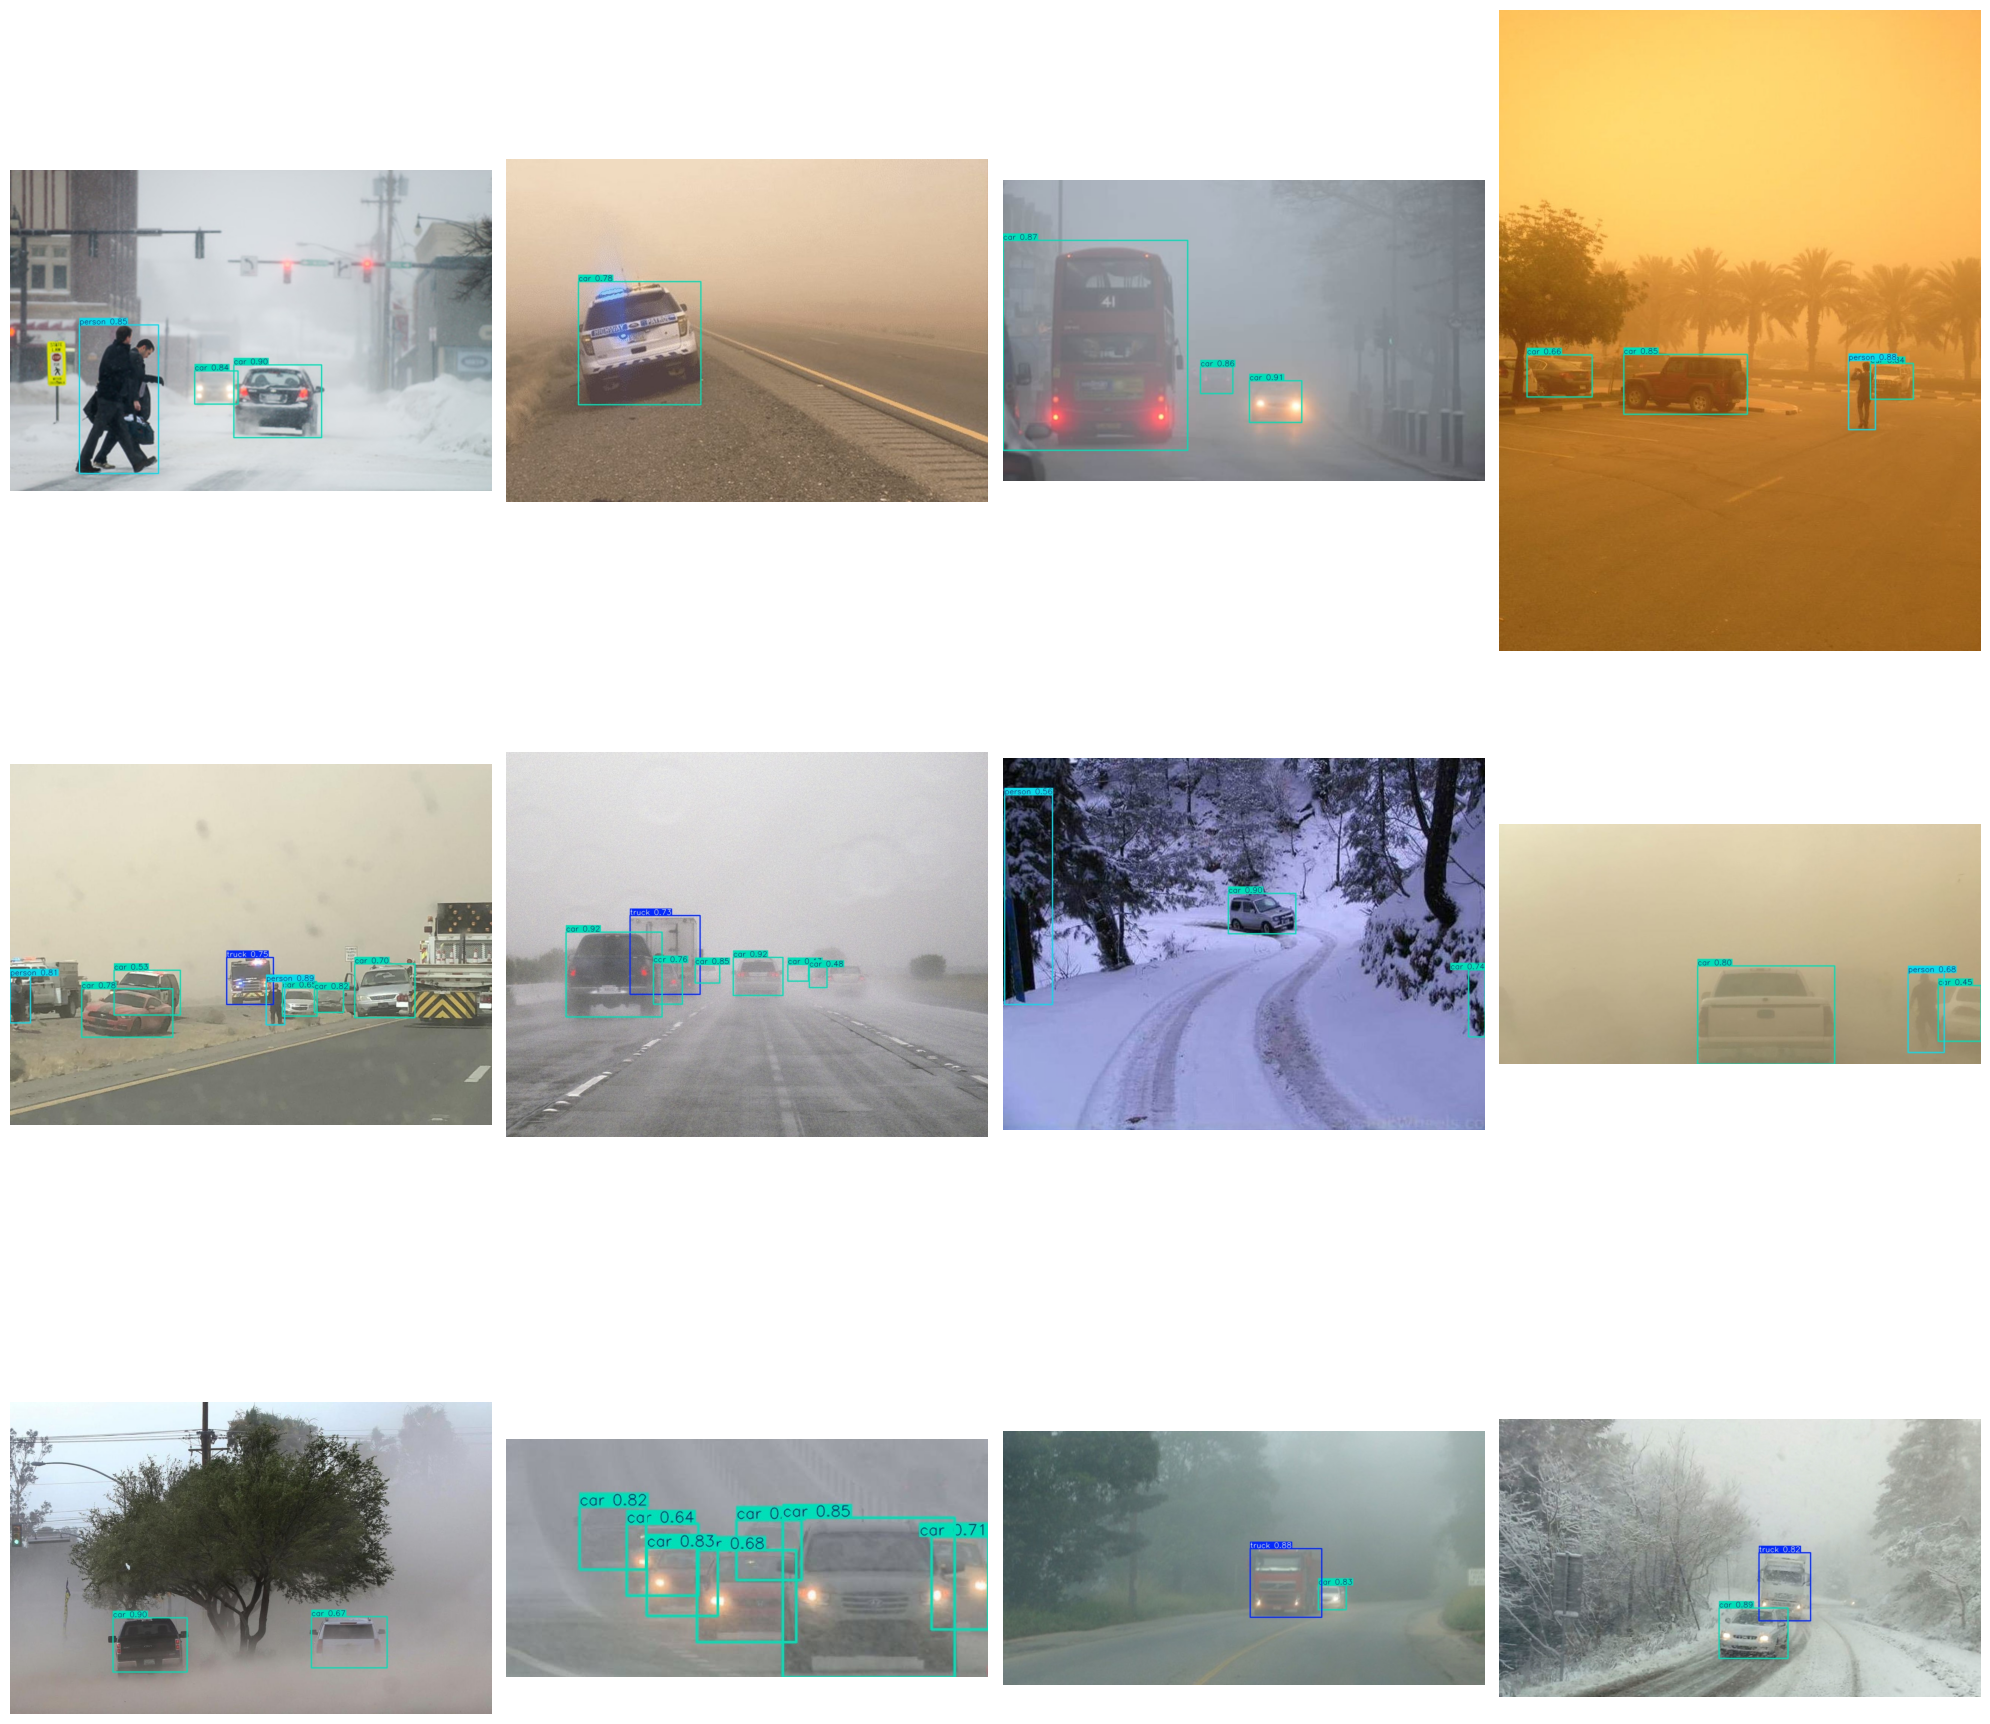

In [ ]:
# 7. Choose random images from the dataset
images_path = "/content/split_yolo/val/images"

image_files = [
    f for f in os.listdir(images_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

num_images = min(12, len(image_files))
imgs = random.sample(image_files, num_images)

plt.figure(figsize=(20, 20))

for c, img in enumerate(imgs, start=1):
    full_img_path = os.path.join(images_path, img)

    # Run predictions and save the annotated image
    results = model.predict(
        source=full_img_path,
        conf=0.4,
        save=True,
        line_width=2,
        show_labels=True
    )

    # Get the path where YOLO saved the prediction
    saved_dir = results[0].save_dir
    saved_img_path = os.path.join(saved_dir, img)

    if os.path.exists(saved_img_path):
        image = plt.imread(saved_img_path)
        plt.subplot(3, 4, c)
        plt.imshow(image)
        plt.axis("off")
    else:
        print(f"Warning: Prediction image not found at {saved_img_path}")

plt.tight_layout()
plt.show()

# Part 8: Class-Weighted Classification Loss

In [ ]:
import ultralytics
import ultralytics.utils.loss as loss_module

file_path = loss_module.__file__
print("File location:", file_path)

print("Showing loss.py:\n")

with open(file_path, "r") as f:
    print(f.read())

File location: /usr/local/lib/python3.13/dist-packages/ultralytics/utils/loss.py
Showing loss.py:

# Ultralytics 🚀 AGPL-3.0 License - https://ultralytics.com/license

from __future__ import annotations

import math
from pathlib import Path
from typing import Any

import torch
import torch.nn.functional as F
from torch import nn

from ultralytics.utils.metrics import CITYSCAPES_WEIGHT, OKS_SIGMA, RLE_WEIGHT
from ultralytics.utils.ops import crop_mask, xywh2xyxy, xyxy2xywh
from ultralytics.utils.tal import (
    PoseTaskAlignedAssigner,
    RotatedTaskAlignedAssigner,
    SegTaskAlignedAssigner,
    TaskAlignedAssigner,
    dist2bbox,
    dist2rbox,
    make_anchors,
)
from ultralytics.utils.torch_utils import autocast, interpolate_bilinear

from .metrics import bbox_iou, probiou
from .tal import bbox2dist, rbox2dist


class VarifocalLoss(nn.Module):
    """Varifocal loss by Zhang et al.

    Implements the Varifocal Loss function for addressing class imbalance in object detection by foc

In [ ]:
# Show the classification-loss code inside v8DetectionLoss
with open(loss_module.__file__, "r") as f:
    lines = f.readlines()

for i, line in enumerate(lines):
    if "class v8DetectionLoss" in line:
        start = i
    if "class v8SegmentationLoss" in line:
        end = i
        break

for i in range(start, end):
    if "self.bce" in lines[i] or "target_scores" in lines[i] or "loss[1]" in lines[i]:
        print(f"{i+1}: {lines[i].rstrip()}")

366:         self.bce = nn.BCEWithLogitsLoss(reduction="none")
452:         _, target_bboxes, target_scores, fg_mask, target_gt_idx = self.assigner(
462:         target_scores_sum = target_scores.sum().clamp_(min=1)  # on the device: no host sync
465:         bce_loss = self.bce(pred_scores, target_scores.to(dtype))  # (bs, num_anchors, nc)
468:         loss[1] = bce_loss.sum() / target_scores_sum  # BCE
476:             target_scores,
477:             target_scores_sum,
484:         loss[1] *= self.hyp.cls  # cls gain


My update

In [ ]:
import glob, numpy as np
NAMES = ['truck','person','bicycle','car','motorcycle','bus']

def count_classes(label_dir, nc=6):
    counts = np.zeros(nc)
    for f in glob.glob(f"{label_dir}/*.txt"):
        for line in open(f):
            if line.strip():
                counts[int(line.split()[0])] += 1
    return counts

train_counts = count_classes("/content/split_yolo/train/labels")

def compute_weights(counts, alpha):
    counts = np.maximum(counts, 1)
    return (counts.sum() / (len(counts) * counts)) ** alpha

print(dict(zip(NAMES, train_counts)))
for a in [0, 0.5, 1]:
    print("alpha =", a, dict(zip(NAMES, compute_weights(train_counts, a).round(2))))

{'truck': np.float64(533.0), 'person': np.float64(364.0), 'bicycle': np.float64(21.0), 'car': np.float64(5279.0), 'motorcycle': np.float64(56.0), 'bus': np.float64(128.0)}
alpha = 0 {'truck': np.float64(1.0), 'person': np.float64(1.0), 'bicycle': np.float64(1.0), 'car': np.float64(1.0), 'motorcycle': np.float64(1.0), 'bus': np.float64(1.0)}
alpha = 0.5 {'truck': np.float64(1.41), 'person': np.float64(1.71), 'bicycle': np.float64(7.12), 'car': np.float64(0.45), 'motorcycle': np.float64(4.36), 'bus': np.float64(2.88)}
alpha = 1 {'truck': np.float64(2.0), 'person': np.float64(2.92), 'bicycle': np.float64(50.64), 'car': np.float64(0.2), 'motorcycle': np.float64(18.99), 'bus': np.float64(8.31)}


In [ ]:
import torch
from ultralytics import YOLO

def train_model(alpha, name, epochs=50, seed=108):
    w = torch.tensor(compute_weights(train_counts, alpha), dtype=torch.float32)

    def set_weights(trainer):
        if alpha > 0:
            trainer.model.class_weights = w

    def check(trainer):
        c = getattr(trainer.model, "criterion", None)
        if c is not None and not getattr(check, "done", False):
            print("CLASS WEIGHTS IN LOSS:", getattr(c, "class_weights", None))
            check.done = True

    model = YOLO("yolov8m.pt")
    model.add_callback("on_train_start", set_weights)
    model.add_callback("on_train_batch_end", check)
    model.train(data="/content/data.yaml", epochs=epochs, imgsz=640, batch=16,
                seed=seed, project=PROJECT, name=name)
    return model

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 11.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


quick 2-epoch test

In [ ]:
test_model = train_model(1.0, "test_alpha1", epochs=2)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=2, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=test_alpha1-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=

In [ ]:
import os

# 1. Check that the split folders still exist
for p in ["/content/split_yolo/train/images", "/content/split_yolo/train/labels",
          "/content/split_yolo/val/images", "/content/split_yolo/val/labels"]:
    print(p, "->", len(os.listdir(p)) if os.path.exists(p) else "DOES NOT EXIST")

# 2. Recreate data.yaml
open("/content/data.yaml", "w").write("""path: /content/split_yolo
train: train/images
val: val/images
nc: 6
names: ['truck','person','bicycle','car','motorcycle','bus']
""")
print(open("/content/data.yaml").read())

/content/split_yolo/train/images -> 821
/content/split_yolo/train/labels -> 821
/content/split_yolo/val/images -> 206
/content/split_yolo/val/labels -> 206
path: /content/split_yolo
train: train/images
val: val/images
nc: 6
names: ['truck','person','bicycle','car','motorcycle','bus']



run (50 epoch weighted inverse)

In [ ]:
model_inverse = train_model(1.0, "weighted_inverse_s108", epochs=50)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weighted_inverse_s108, nbs=64, nms=None, opset=None, optimize=False, o

2nd run (50 epoch weight squre root)

In [ ]:
model_sqrt = train_model(0.5, "weighted_sqrt_s108", epochs=50)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=weighted_sqrt_s108, nbs=64, nms=None, opset=None, optimize=False, opti

3rd run (50 epoch unweighted baseline)

In [ ]:
model_base = train_model(0.0, "baseline_s108", epochs=50)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=baseline_s108, nbs=64, nms=None, opset=None, optimize=False, optimizer

generate a table

In [ ]:
import pandas as pd
from pathlib import Path
from ultralytics import YOLO

runs = {
    "baseline_s108": "/content/drive/MyDrive/csc490_runs/baseline_s108/weights/best.pt",
    "weighted_sqrt_s108": "/content/drive/MyDrive/csc490_runs/weighted_sqrt_s108/weights/best.pt",
    "weighted_inverse_s108": "/content/drive/MyDrive/csc490_runs/weighted_inverse_s108/weights/best.pt",
}

rows = []
for run_name, weights_path in runs.items():
    if not Path(weights_path).exists():
        print(f"Skipping {run_name} (not found yet): {weights_path}")
        continue
    m = YOLO(weights_path)
    res = m.val(data="/content/data.yaml", split="val", verbose=False)

    # Overall row
    rows.append({
        "run": run_name,
        "class": "ALL",
        "precision": round(float(res.box.mp), 4),
        "recall": round(float(res.box.mr), 4),
        "map50": round(float(res.box.map50), 4),
        "map50_95": round(float(res.box.map), 4),
    })

    # Per-class rows
    for idx, cls_name in res.names.items():
        p, r, ap50, ap = res.box.class_result(idx)
        rows.append({
            "run": run_name,
            "class": cls_name,
            "precision": round(float(p), 4),
            "recall": round(float(r), 4),
            "map50": round(float(ap50), 4),
            "map50_95": round(float(ap), 4),
        })

df_summary = pd.DataFrame(rows)
out_csv = "/content/drive/MyDrive/csc490_runs/comparison_50ep_s108.csv"
df_summary.to_csv(out_csv, index=False)
print(f"Saved summary to {out_csv}")
display(df_summary)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,843,234 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1621.3±474.8 MB/s, size: 100.1 KB)
val: Scanning /content/split_yolo/val/labels.cache... 206 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 206/206 54.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 2.0it/s 6.4s
                   all        206       1464      0.637      0.629       0.61      0.391
Speed: 1.4ms preprocess, 14.0ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 92 layers, 25,843,234 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1990.8±970.1 MB/s, size: 168.1 KB)
val: Scanning /content/s

,run,class,precision,recall,map50,map50_95
0,baseline_s108,ALL,0.6372,0.6292,0.6101,0.3908
1,baseline_s108,truck,0.5911,0.6372,0.6535,0.4425
2,baseline_s108,person,0.7167,0.7838,0.8061,0.4632
3,baseline_s108,bicycle,0.5890,0.5779,0.4350,0.2649
4,baseline_s108,car,0.7730,0.9123,0.9176,0.6284
5,baseline_s108,motorcycle,0.6635,0.4400,0.4448,0.2184
6,baseline_s108,bus,0.4900,0.4242,0.4035,0.3271
7,weighted_sqrt_s108,ALL,0.7520,0.5327,0.6248,0.3711
8,weighted_sqrt_s108,truck,0.7097,0.5575,0.6469,0.4261
9,weighted_sqrt_s108,person,0.8062,0.6628,0.7727,0.4620
